# Telangana PDS Analytics
## Multi-Dimensional Shop Performance Clustering and Anomaly Profiling

**Goal:** group Telangana's ~17,500 Fair Price Shops (FPS) by *how they behave*, then flag shops that behave
unlike their peers. Those can point to ghost beneficiaries or stock diversion. We also look at how One Nation
One Ration Card (ONORC) portability has changed shop behaviour, and which shops are "portability hubs" that need
more frequent restocking.

**Data:** Telangana Open Data Portal, Jan 2023 to May 2025:
* *FP Shop Wise Transactions*: monthly transactions and commodities per shop
* *FP Shop Card Status*: monthly ration-card counts per shop (entitlement)
* *FP Shop Latitude/Longitude*: shop locations

**Notebook map**
1. Data integration
2. Exploratory data analysis (EDA)
3. Feature engineering
4. Scaling and PCA
5. K-Means: choosing k, fitting, profiling personas
6. DBSCAN and peer-deviation anomalies
7. Evaluation and business insights

In [1]:
import sys, json
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))   # notebook lives in notebooks/, code in src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import PROCESSED_DIR, FIGURES_DIR
import data_prep, features, modeling

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:,.3f}".format)

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=140)

## 1. Data integration

The portal publishes **one CSV per month** for each dataset. `src/download_data.py` fetched 29 transaction files,
30 card-status files and 1 location file. `data_prep.build_master()` then:

1. **Stacks** the monthly files of each dataset with `pd.concat` (same columns, so they stack vertically).
2. **Left-joins** card status onto transactions on the full shop-month key `(distCode, shopNo, year, month)`.
3. **Left-joins** locations on the shop key `(distCode, shopNo)`.

> **Concept: join keys and `validate`.** `shopNo` alone isn't guaranteed unique across districts, so we join on
> `distCode + shopNo`. `validate="one_to_one"` makes pandas raise an error if a key is duplicated, so a bad
> join can't silently multiply rows.

In [2]:
master = pd.read_parquet(PROCESSED_DIR / "master_monthly.parquet")
print(f"{len(master):,} shop-month rows | {master[['distCode','shopNo']].drop_duplicates().shape[0]:,} shops | "
      f"{master['distName'].nunique()} districts | {master['date'].min():%b %Y} to {master['date'].max():%b %Y}")
master.head()

499,648 shop-month rows | 17,491 shops | 33 districts | Jan 2023 to May 2025


,distCode,distName,officeCode,officeName,shopNo,month,year,noOfRcs,noOfTrans,riceAfsc,...,totalRcState,totalRcs,totalUnits,address,latitude,longitude,fpsStatus,fpsType,date,area_type
0,532,Adilabad,532001,Talamadugu,1901001,1,2023,973,973,"1,365.000",...,152.000,"1,108.000","3,397.000",DR Depo TALAMADUGU Talamadugu,19.642,78.391,Active,Normal Shop,2023-01-01,Rural
1,532,Adilabad,532001,Talamadugu,1901002,1,2023,519,519,665.000,...,316.000,584.000,"1,881.000",Sunkari Ramesh Sunkidi,19.669,78.422,Active,Normal Shop,2023-01-01,Rural
2,532,Adilabad,532001,Talamadugu,1901003,1,2023,255,255,490.000,...,124.000,293.000,955.000,Sakipelli Gajanan Umdam,19.665,78.427,Active,Normal Shop,2023-01-01,Rural
3,532,Adilabad,532001,Talamadugu,1901004,1,2023,361,362,490.000,...,207.000,405.000,"1,353.000",Rebbathi Rakesh Lingi,19.696,78.381,Active,Normal Shop,2023-01-01,Rural
4,532,Adilabad,532001,Talamadugu,1901005,1,2023,896,897,"5,320.000",...,290.000,971.000,"3,345.000",T Manohar Kuchulapur,19.697,78.351,Active,Normal Shop,2023-01-01,Rural


In [3]:
# Data quality: what's missing after the joins?
miss = master[["totalRcs", "latitude", "longitude", "fpsStatus"]].isna().mean().mul(100).round(2)
print("Missing % after joins:"); print(miss.to_string())
print("\nMonths per year:", master.groupby("year")["month"].nunique().to_dict())

Missing % after joins:
totalRcs    0.030
latitude    1.570
longitude   1.570
fpsStatus   0.880

Months per year: {2023: 12, 2024: 12, 2025: 5}


Only ~0.03% of shop-months lack a card count and ~1.6% of shops lack valid coordinates (out-of-state
coordinates were blanked in `load_locations`). **2025 has only Jan to May**, so we compare years with
*ratios* rather than totals.

Column glossary:

| column | meaning |
|---|---|
| `totalRcs` | ration cards attached to the shop (entitlement) |
| `noOfTrans` | transactions recorded that month |
| `otherShopTransCnt` | transactions by cards from **other** shops (ONORC portability) |
| `riceAfsc / riceFsc / riceAap` | rice kg under the Antyodaya / Food Security / Annapurna schemes, summed into `rice` |
| `rcNfsaAay` | Antyodaya Anna Yojana cards (poorest households) |

## 2. Exploratory data analysis

### 2.1 Portability trend: ONORC adoption, Urban vs Rural

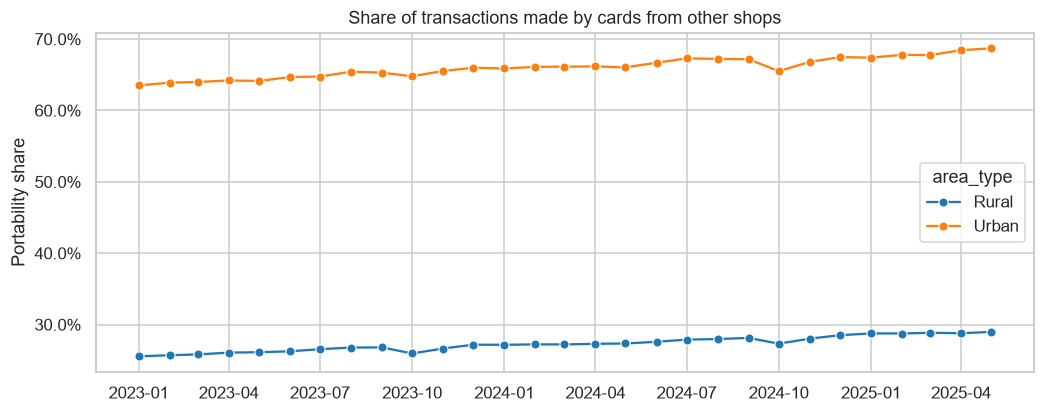

area_type,Rural,Urban
date,,
2023,26.3%,64.7%
2024,27.6%,66.5%
2025,28.8%,68.0%


In [4]:
t = master.groupby(["date", "area_type"]).agg(trans=("noOfTrans","sum"), port=("otherShopTransCnt","sum")).reset_index()
t["portability_share"] = t["port"] / t["trans"]

fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=t, x="date", y="portability_share", hue="area_type", marker="o", ax=ax)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title="Share of transactions made by cards from other shops", xlabel="", ylabel="Portability share")
save(fig, "01_portability_trend"); plt.show()

yearly = t.groupby([t["date"].dt.year, "area_type"])[["port","trans"]].sum()
(yearly["port"] / yearly["trans"]).unstack().style.format("{:.1%}")

**Reading it:** in urban shops (Hyderabad, Medchal, Ranga Reddy) about **two-thirds of transactions**
(65% in 2023, 68% in 2025) come from cards registered at another shop. In rural shops it's about a quarter
(26% to 29%). Migrant workers draw rations near where they live and work, not where their card is registered.
Portability is **still rising every year in both zones**, so ONORC adoption hasn't plateaued.

### 2.2 Entitlement vs actual: `totalRcs` vs `noOfTrans`
> **Concept: correlation.** Pearson's *r* measures how closely two variables follow a straight line (-1 to 1).
> A high *r* here means busy shops are simply shops with more cards. Points **far from the line** are interesting:
> shops transacting much more (or less) than their card base supports.

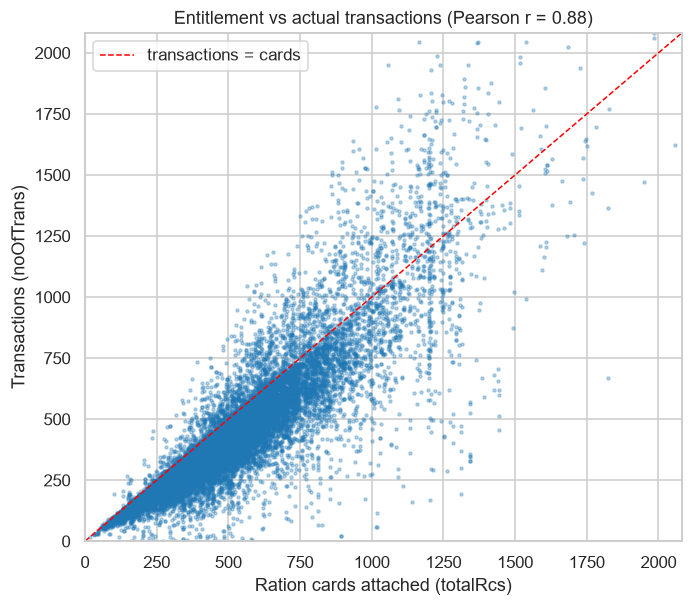

In [5]:
shop_month = master.dropna(subset=["totalRcs"])
r = shop_month[["totalRcs", "noOfTrans"]].corr().iloc[0, 1]
s = shop_month.sample(20000, random_state=1)
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(s["totalRcs"], s["noOfTrans"], s=4, alpha=0.3)
lim = s[["totalRcs","noOfTrans"]].quantile(0.999).max()
ax.plot([0, lim], [0, lim], "r--", lw=1, label="transactions = cards")
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Ration cards attached (totalRcs)", ylabel="Transactions (noOfTrans)",
       title=f"Entitlement vs actual transactions (Pearson r = {r:.2f})")
ax.legend(); save(fig, "02_cards_vs_transactions"); plt.show()

Most shops sit just **below** the red line: not every card collects every month. Shops **above** the line
transact more often than they have cards. Portability explains part of that, but it's also the pattern to watch
for duplicate draws.

### 2.3 Rice and wheat distribution by district

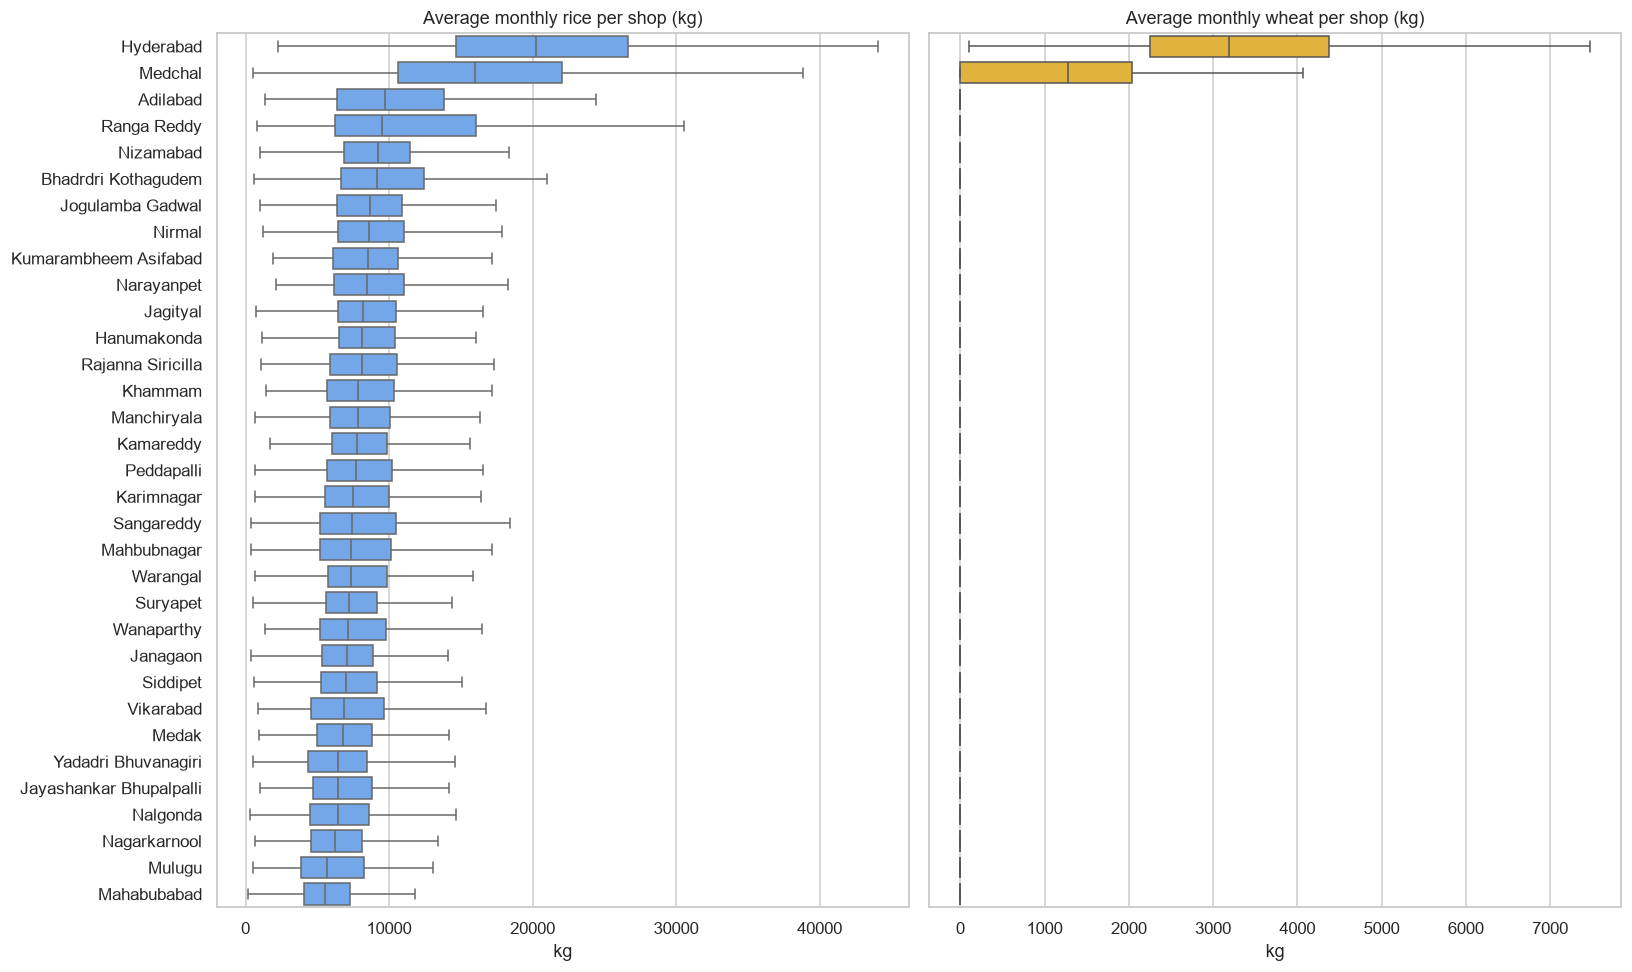

In [6]:
dm = master.groupby(["distName", "distCode", "shopNo"]).agg(rice=("rice","mean"), wheat=("wheat","mean")).reset_index()
order = dm.groupby("distName")["rice"].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharey=True)
sns.boxplot(data=dm, y="distName", x="rice", order=order, ax=axes[0], showfliers=False, color="#60a5fa")
axes[0].set(title="Average monthly rice per shop (kg)", xlabel="kg", ylabel="")
sns.boxplot(data=dm, y="distName", x="wheat", order=order, ax=axes[1], showfliers=False, color="#fbbf24")
axes[1].set(title="Average monthly wheat per shop (kg)", xlabel="kg", ylabel="")
plt.tight_layout(); save(fig, "03_rice_wheat_by_district"); plt.show()

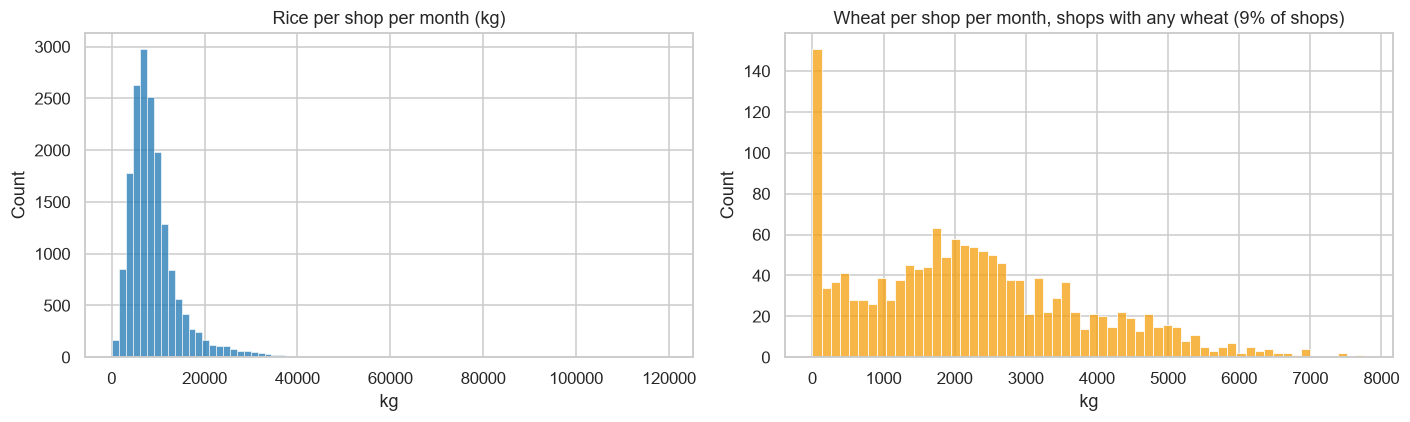

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(dm["rice"], bins=80, ax=axes[0]); axes[0].set(title="Rice per shop per month (kg)", xlabel="kg")
sns.histplot(dm.loc[dm["wheat"] > 0, "wheat"], bins=60, ax=axes[1], color="#f59e0b")
axes[1].set(title=f"Wheat per shop per month, shops with any wheat ({(dm['wheat']>0).mean():.0%} of shops)", xlabel="kg")
plt.tight_layout(); save(fig, "04_rice_wheat_hist"); plt.show()

Rice dominates everywhere. Wheat is only distributed by a minority of shops, mostly in the urban districts.
That's why **commodity mix** (`wheat_share`) separates urban hubs from rural shops. Both distributions are
right-skewed (a long tail of very large shops), which is one reason we log-transform shop size later.

### 2.4 Seasonality: monthly spikes

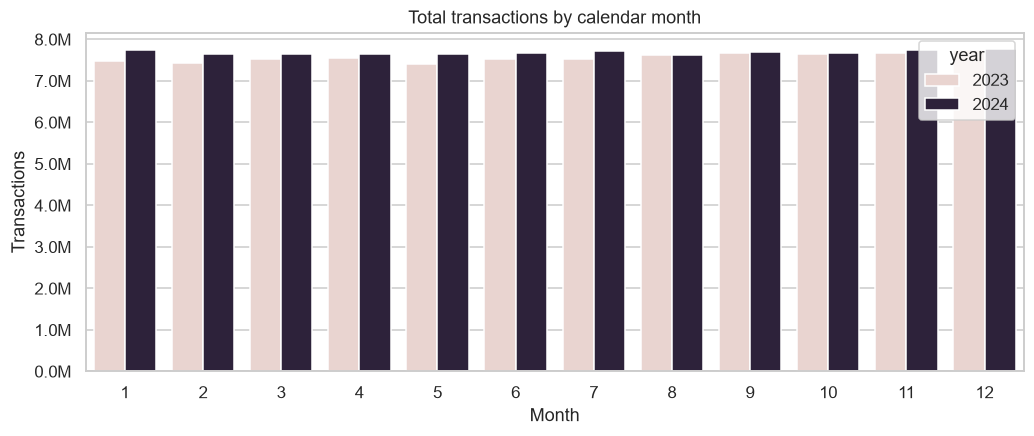

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2023,0.988,0.980,0.995,0.999,0.979,0.995,0.995,1.006,1.014,1.012,1.013,1.024
2024,1.007,0.996,0.996,0.993,0.994,0.999,1.005,0.990,1.002,0.999,1.006,1.011


In [8]:
mon = master[master["year"].isin([2023, 2024])].groupby(["year", "month"])["noOfTrans"].sum().reset_index()
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=mon, x="month", y="noOfTrans", hue="year", ax=ax)
ax.set(title="Total transactions by calendar month", xlabel="Month", ylabel="Transactions")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"))
save(fig, "05_seasonality"); plt.show()

idx = mon.pivot(index="month", columns="year", values="noOfTrans")
(idx / idx.mean()).round(3).T

The index table divides each month by the year's average (1.00 = a typical month). **Seasonality is
surprisingly flat:** every month is within about ±2.5% of the average. The one consistent pattern is a mild
rise from August to December in 2023 (up to +2.4% in December), around the festival and kharif-harvest season.
This makes sense because PDS rations are a fixed *monthly entitlement*, not discretionary shopping. Demand
doesn't spike, so **a shop that does spike is unusual for that reason alone**. That's why monthly volatility
(`trans_cv`) is a useful anomaly feature.

## 3. Feature engineering

Raw totals mostly measure **shop size**. Clustering on them would just give "big shops vs small shops". So we
build **ratios** that describe *behaviour* at the **shop-year** level (one row per shop per year). That lets
the dashboard filter by year and lets us track how shops move between personas over time.

| feature | formula | why it matters |
|---|---|---|
| `log_avg_cards` | log(1 + mean cards) | size, log-scaled so a few huge shops don't dominate |
| `utilization_ratio` | transactions / cards | ~1 = every card collects. Far above 1 is a ghost-draw risk, far below is low uptake |
| `portability_share` | other-shop transactions / transactions | ONORC dependence, i.e. a "portability hub" signal |
| `rice_per_trans` | rice kg / transactions | unusually high values can mean diversion |
| `wheat_share` | wheat / (rice + wheat) | commodity intensity (a bounded form of the rice-to-wheat ratio) |
| `aay_share` | Antyodaya cards / all cards | poverty profile of the catchment |
| `trans_cv` | std / mean of monthly transactions | volatility. Erratic shops are harder to stock and to trust |

> **Why `wheat_share` instead of rice-to-wheat ratio?** Most shops get **zero** wheat, so rice/wheat divides by
> zero (infinity). A share between 0 and 1 carries the same information without breaking the maths.

`active_month_share` was also tested, but almost every shop is active every month, so it has no variance and was
dropped from the model. **Feature selection rule:** keep a feature only if it varies across shops *and* answers
one of the business questions.

In [9]:
feats = features.shop_year_features(master)
df = pd.read_parquet(PROCESSED_DIR / "shop_year_clusters.parquet")   # model_ready + model outputs
print(f"{len(feats):,} shop-years built, {len(df):,} kept for modelling "
      f"(dropped shops with <20 cards or no transactions)")
df[features.MODEL_FEATURES].describe().T

51,960 shop-years built, 51,904 kept for modelling (dropped shops with <20 cards or no transactions)


,count,mean,std,min,25%,50%,75%,max
log_avg_cards,"51,904.000",6.151,0.483,3.434,5.889,6.182,6.450,8.532
utilization_ratio,"51,904.000",0.839,0.182,0.006,0.743,0.838,0.927,2.100
portability_share,"51,904.000",0.286,0.274,0.000,0.058,0.163,0.486,1.000
rice_per_trans,"51,904.000",20.456,2.083,2.796,18.949,20.236,21.685,34.922
wheat_share,"51,904.000",0.009,0.032,0.000,0.000,0.000,0.000,0.631
aay_share,"51,904.000",0.069,0.049,0.000,0.043,0.061,0.081,0.946
trans_cv,"51,904.000",0.064,0.084,0.000,0.023,0.040,0.072,1.776


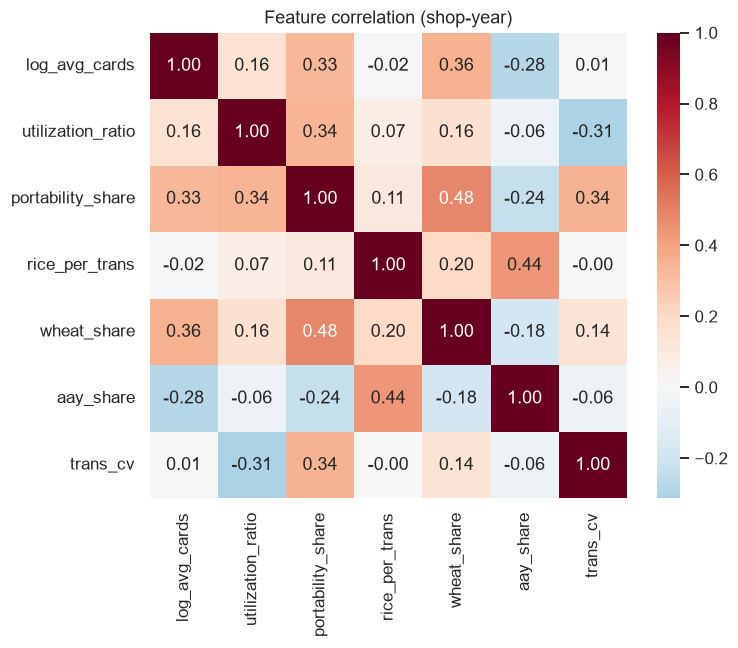

In [10]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df[features.MODEL_FEATURES].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Feature correlation (shop-year)")
save(fig, "06_feature_correlation"); plt.show()

No pair of features is almost perfectly correlated (|r| > 0.9), so each one adds its own information.
Size and portability are positively linked (big urban shops attract outside cards). That's real behaviour,
not redundancy.

## 4. Scaling and PCA

> **Concept: StandardScaler.** K-Means and DBSCAN compare shops by *distance*. `log_avg_cards` ranges 3-9 while
> `wheat_share` ranges 0-0.3. Without scaling, size would decide every distance. StandardScaler converts each
> feature to *z-scores* (mean 0, std 1), giving every feature an equal vote. Before scaling we also clip the
> extreme 0.1% at each end, so a few typos can't stretch the scale.

> **Concept: PCA.** Principal Component Analysis finds new axes (combinations of features) that capture the most
> variance. PC1 is the single direction along which shops differ most, PC2 the next (at right angles), and so on.
> We use 3 components to *visualise* clusters and to run DBSCAN in a compact space.

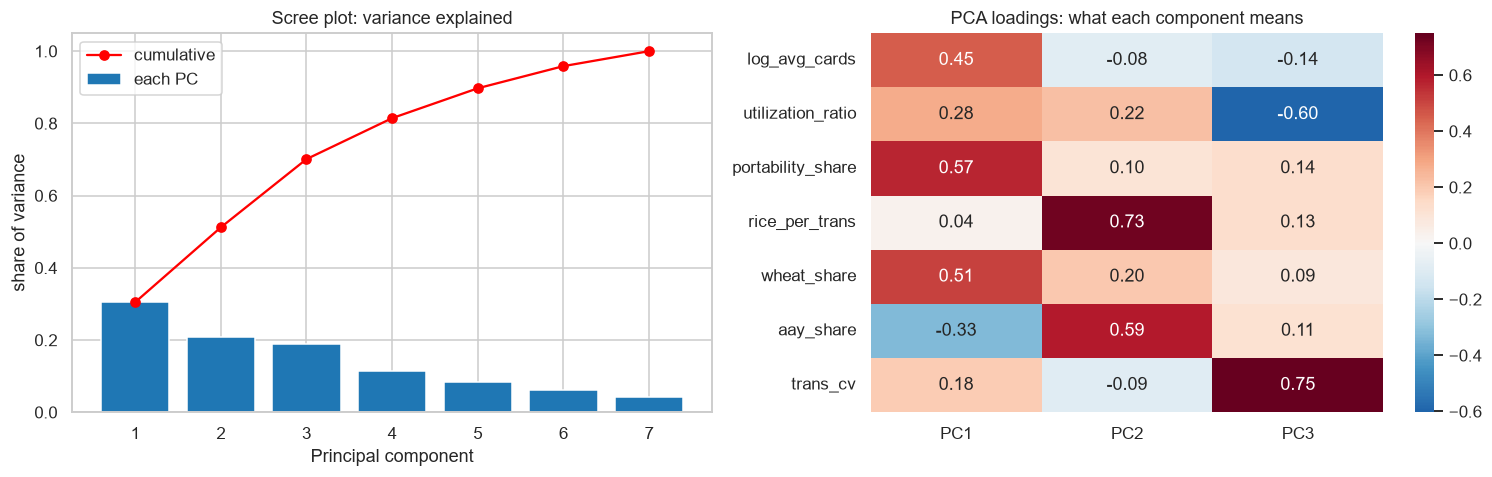

Cumulative variance of first 3 PCs: 70.1%


In [11]:
X, scaler = modeling.scale(df)
Z, pca = modeling.fit_pca(X, n_components=len(features.MODEL_FEATURES))
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, len(ev)+1), ev, label="each PC")
axes[0].plot(range(1, len(ev)+1), ev.cumsum(), "ro-", label="cumulative")
axes[0].set(title="Scree plot: variance explained", xlabel="Principal component", ylabel="share of variance")
axes[0].legend()
load = pd.DataFrame(pca.components_[:3].T, index=features.MODEL_FEATURES, columns=["PC1","PC2","PC3"])
sns.heatmap(load, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("PCA loadings: what each component means")
plt.tight_layout(); save(fig, "07_pca_scree_loadings"); plt.show()
print("Cumulative variance of first 3 PCs:", f"{ev[:3].sum():.1%}")

**Interpreting the loadings:** a large positive or negative number means that feature drives the component.
* **PC1 (30%) = "urban hub" axis:** portability, wheat share and size load positively, and Antyodaya share
  negatively. Big metro shops are on the right, small poor rural shops on the left.
* **PC2 (21%) = "poverty / ration-size" axis:** rice per transaction and Antyodaya share (AAY cards get 35 kg).
* **PC3 (19%) = "irregularity" axis:** high volatility combined with *low* utilization.

The first three components keep 70% of the information in the seven features.

## 5. K-Means clustering

> **Concept: K-Means.** Choose *k* centres, assign every shop to its nearest centre, move each centre to the
> mean of its shops, and repeat until nothing changes. It minimises **inertia** (total squared distance of shops to
> their centre).
>
> **Choosing k:**
> * **Elbow curve:** inertia always drops as k grows. Look for the bend where extra clusters stop helping much.
> * **Silhouette score:** for each shop, (distance to nearest *other* cluster minus distance to own cluster) / max of
>   the two. Ranges -1 to 1. Higher means tighter, better-separated clusters.

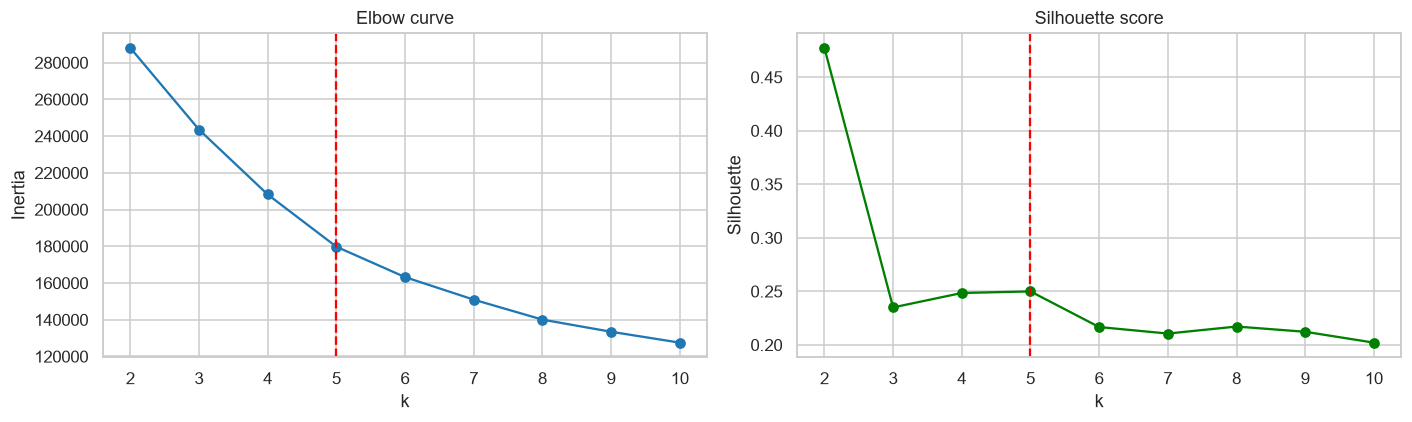

,k,inertia,silhouette
0,2,"288,049.086",0.477
1,3,"243,534.077",0.235
2,4,"208,204.192",0.248
3,5,"179,747.644",0.250
4,6,"163,198.302",0.217
5,7,"150,926.637",0.211
6,8,"140,051.641",0.217
7,9,"133,439.871",0.212
8,10,"127,509.521",0.202


In [12]:
ks = pd.read_csv(PROCESSED_DIR / "k_search.csv")
meta = json.loads((PROCESSED_DIR / "model_meta.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks["k"], ks["inertia"], "o-"); axes[0].axvline(meta["k"], ls="--", c="r")
axes[0].set(title="Elbow curve", xlabel="k", ylabel="Inertia")
axes[1].plot(ks["k"], ks["silhouette"], "o-", c="green"); axes[1].axvline(meta["k"], ls="--", c="r")
axes[1].set(title="Silhouette score", xlabel="k", ylabel="Silhouette")
plt.tight_layout(); save(fig, "08_elbow_silhouette"); plt.show()
ks

**Decision: k = 5.**
* k = 2 has the highest silhouette, but it only splits "urban hubs vs everything else". That's too coarse to
  act on.
* Among the k values the brief asks for (4-5 personas), **k = 5 has the best silhouette (≈0.25)**, and the
  elbow curve flattens after about 5.
* A silhouette of 0.25 is typical for real behavioural data: shops sit on a continuum rather than in sharply
  separated blobs. The personas are useful *segments*, not perfectly separate species.

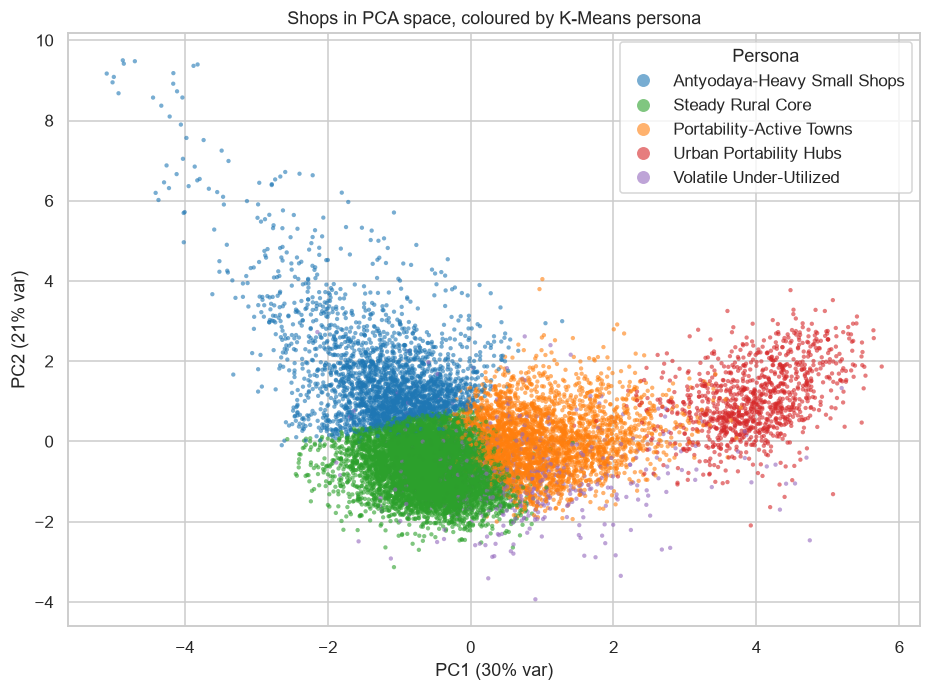

In [13]:
pal = dict(zip(sorted(df["persona"].unique()), sns.color_palette("tab10")))
s = df.sample(15000, random_state=0)
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=s, x="pc1", y="pc2", hue="persona", palette=pal, s=8, alpha=0.6, linewidth=0, ax=ax)
ax.set(title="Shops in PCA space, coloured by K-Means persona",
       xlabel=f"PC1 ({meta['pca_explained_variance'][0]:.0%} var)", ylabel=f"PC2 ({meta['pca_explained_variance'][1]:.0%} var)")
ax.legend(markerscale=3, title="Persona")
save(fig, "09_pca_clusters"); plt.show()

### 5.1 Cluster profiling: giving clusters names
A cluster number means nothing to a policymaker. We compute each cluster's **mean features** and name it after
what makes it stand out (`modeling.name_personas` picks the most distinctive feature for each cluster).

In [14]:
prof = pd.read_csv(PROCESSED_DIR / "cluster_profiles.csv", index_col="persona")
prof.style.format(precision=3).background_gradient(axis=0, cmap="Blues")

,shops,urban_pct,avg_cards,avg_monthly_trans,utilization_ratio,portability_share,rice_per_trans,wheat_share,aay_share,trans_cv,dbscan_noise_pct,anomaly_pct
persona,,,,,,,,,,,,
Antyodaya-Heavy Small Shops,8975,11.242,376.483,307.763,0.818,0.130,23.078,0.000,0.131,0.044,1.404,3.120
Portability-Active Towns,10885,10.528,612.323,595.565,0.968,0.592,20.457,0.001,0.054,0.067,0.266,5.071
Steady Rural Core,26623,2.772,482.653,382.647,0.795,0.130,19.391,0.000,0.059,0.043,0.030,0.428
Urban Portability Hubs,3514,100.000,943.520,931.813,0.994,0.777,21.971,0.121,0.035,0.092,2.334,2.760
Volatile Under-Utilized,1907,11.799,480.103,249.200,0.538,0.548,20.195,0.008,0.060,0.368,19.717,19.874


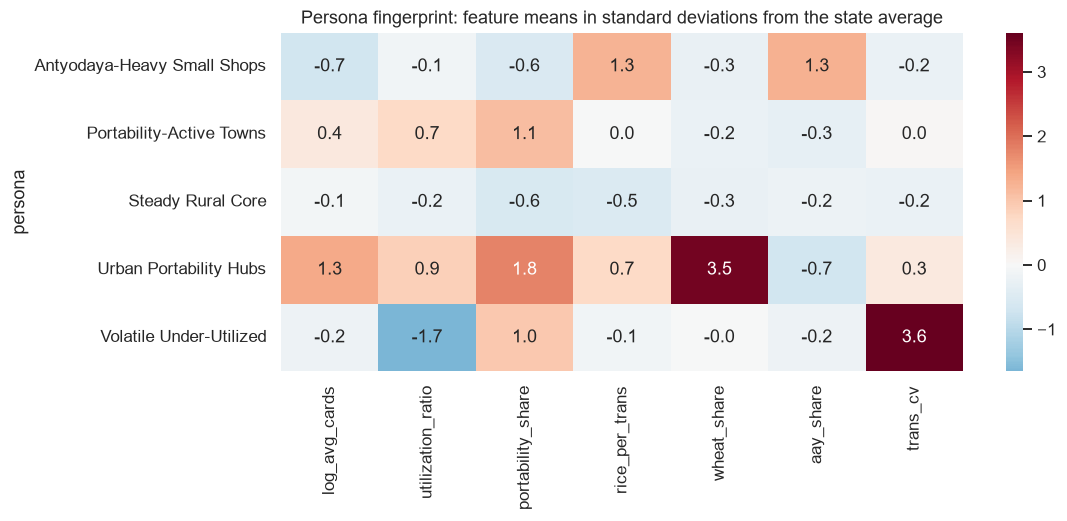

In [15]:
z = df.groupby("persona")[features.MODEL_FEATURES].mean()
z = (z - df[features.MODEL_FEATURES].mean()) / df[features.MODEL_FEATURES].std()
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Persona fingerprint: feature means in standard deviations from the state average")
save(fig, "10_persona_fingerprint"); plt.show()

| Persona | What defines it | Typical action |
|---|---|---|
| **Steady Rural Core** | the majority: average size, ~13% portability, low volatility | routine monitoring |
| **Antyodaya-Heavy Small Shops** | small shops, highest share of poorest (AAY) cards, most rice per transaction | protect supply, since vulnerable households depend on them |
| **Portability-Active Towns** | larger shops where ~60% of transactions come from other shops' cards | buffer stock for ONORC demand |
| **Urban Portability Hubs** | entirely in the Hyderabad metro, largest shops, ~78% portability, the only real wheat users | most frequent restocking |
| **Volatile Under-Utilized** | erratic monthly volumes, only ~54% card utilization | audit first: highest anomaly rate |

(The exact numbers are in the profile table above.)

## 6. Anomaly detection

### 6.1 DBSCAN: shops that fit no pattern
> **Concept: DBSCAN** (Density-Based Spatial Clustering of Applications with Noise). A point is a *core* point if at
> least `min_samples` neighbours lie within radius `eps`. Clusters grow from core points. Any point not reachable
> from a dense region gets the label **-1 = noise**. Unlike K-Means, DBSCAN doesn't force every shop into a group,
> which is exactly what we want for outliers.
>
> **Choosing the parameters:** `min_samples = 2 × dimensions = 6` (a common rule of thumb). For `eps` we plot the
> sorted distance of each point to its 6th neighbour (the *k-distance plot*) and take the point where the curve
> bends sharply upward. Points beyond the bend live in sparse regions.

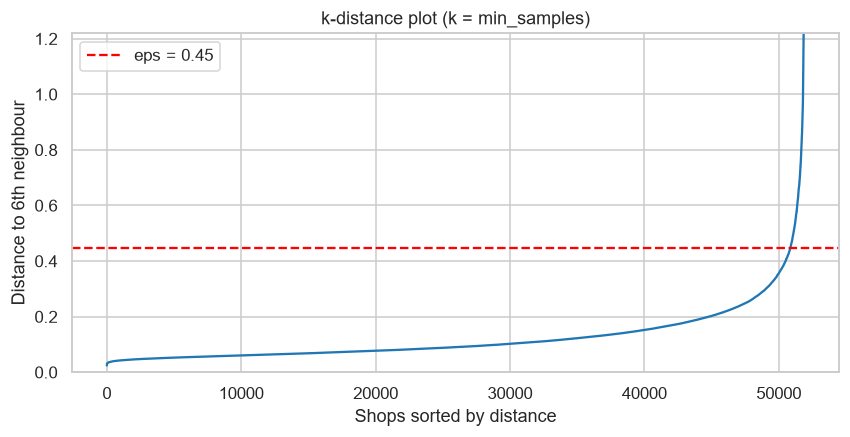

DBSCAN noise points: 621 shop-years (1.2%)


persona
Antyodaya-Heavy Small Shops    1.400
Portability-Active Towns       0.270
Steady Rural Core              0.030
Urban Portability Hubs         2.330
Volatile Under-Utilized       19.720
Name: noise %, dtype: float64

In [16]:
Z3 = df[["pc1","pc2","pc3"]].to_numpy()
kd = modeling.k_distance(Z3, meta["dbscan_min_samples"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(kd); ax.axhline(meta["dbscan_eps"], c="r", ls="--", label=f"eps = {meta['dbscan_eps']:.2f}")
ax.set(title="k-distance plot (k = min_samples)", xlabel="Shops sorted by distance", ylabel="Distance to 6th neighbour")
ax.set_ylim(0, kd[int(len(kd)*0.999)]); ax.legend()
save(fig, "11_dbscan_kdistance"); plt.show()

print(f"DBSCAN noise points: {meta['dbscan_noise_count']:,} shop-years ({meta['dbscan_noise_count']/len(df):.1%})")
df.groupby("persona")["dbscan_noise"].mean().mul(100).round(2).rename("noise %")

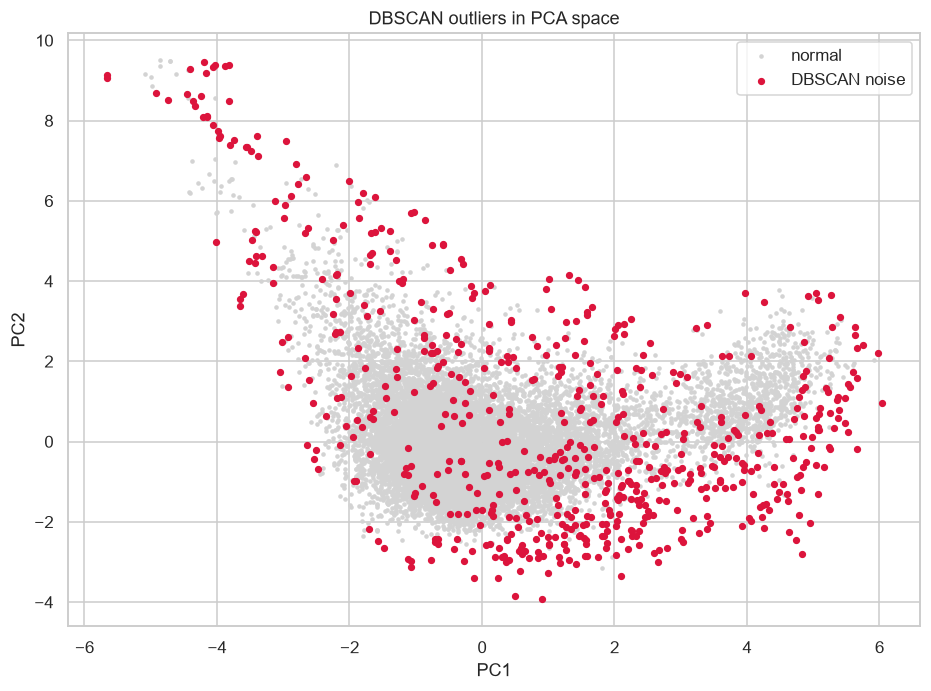

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))
norm = df[~df["dbscan_noise"]].sample(15000, random_state=0)
ax.scatter(norm["pc1"], norm["pc2"], s=4, c="lightgrey", label="normal")
noise = df[df["dbscan_noise"]]
ax.scatter(noise["pc1"], noise["pc2"], s=14, c="crimson", label="DBSCAN noise")
ax.set(title="DBSCAN outliers in PCA space", xlabel="PC1", ylabel="PC2"); ax.legend()
save(fig, "12_dbscan_outliers"); plt.show()

### 6.2 Peer deviation: fraud screening against the shop's own cluster
A shop with utilization 1.3 might be normal for an urban hub but alarming for a rural shop. So we compare each
shop **only to its own persona** using a **robust z-score**:

$$ z = 0.6745 \times \frac{x - \text{median}}{\text{MAD}} $$

> **Concept: robust z-score.** The usual z-score uses mean and standard deviation, which are themselves pulled by
> the outliers we're trying to find. Median and MAD (median absolute deviation) aren't. |z| > 3.5 is the standard
> cut-off (Iglewicz & Hoaglin).

We score `utilization_ratio` (ghost-beneficiary signal) and `rice_per_trans` (diversion signal).

Peer outliers (|z| > 3.5): 912  |  flagged by either method: 1,422 shop-years (2.7%)


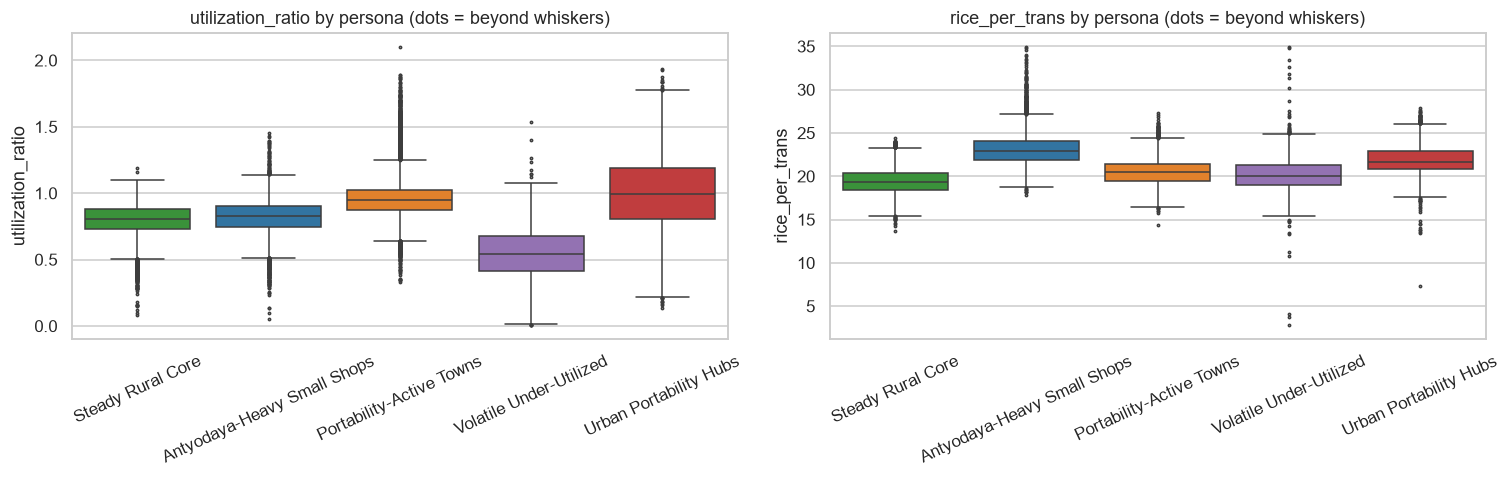

In [18]:
print(f"Peer outliers (|z| > 3.5): {meta['peer_outlier_count']:,}  |  "
      f"flagged by either method: {int(df['anomaly_flag'].sum()):,} shop-years ({df['anomaly_flag'].mean():.1%})")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, f in zip(axes, ["utilization_ratio", "rice_per_trans"]):
    sns.boxplot(data=df, x="persona", y=f, ax=ax, showfliers=True, fliersize=1.5, palette=pal, hue="persona", legend=False)
    ax.set(title=f"{f} by persona (dots = beyond whiskers)", xlabel=""); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); save(fig, "13_peer_deviation_boxplots"); plt.show()

In [19]:
anom = pd.read_csv(PROCESSED_DIR / "anomalies.csv")
print("Top 15 most deviant shop-years:")
anom.head(15)

Top 15 most deviant shop-years:


,distName,officeName,shopNo,year,persona,avg_cards,avg_monthly_trans,utilization_ratio,rice_per_trans,portability_share,z_utilization_ratio,z_rice_per_trans,dbscan_noise,peer_outlier
0,Ranga Reddy,Abdullapurmet,1596009,2023,Portability-Active Towns,148.167,311.167,2.100,20.689,0.923,10.260,0.171,False,True
1,Medchal,Balanagar-1,3384048,2025,Urban Portability Hubs,642.000,187.600,0.292,7.382,0.956,-2.439,-9.885,True,True
2,Medchal,Balanagar-1,3384048,2024,Volatile Under-Utilized,642.000,164.500,0.256,2.796,0.959,-1.459,-9.768,True,True
3,Medchal,Balanagar-1,3384048,2023,Volatile Under-Utilized,582.200,114.800,0.197,3.775,0.991,-1.757,-9.215,True,True
4,Medchal,Balanagar-1,3384049,2024,Volatile Under-Utilized,465.000,121.500,0.261,4.139,0.986,-1.434,-9.009,True,True
5,Peddapalli,PEDDAPALLI,3610016,2024,Volatile Under-Utilized,401.000,24.417,0.061,34.922,0.894,-2.444,8.390,True,True
6,Sangareddy,Ameenpur,3702005,2023,Portability-Active Towns,710.750,"1,342.667",1.889,20.510,0.577,8.384,0.051,False,True
7,Nalgonda,Devarakonda,2357014,2023,Portability-Active Towns,180.000,340.000,1.889,19.245,0.994,8.382,-0.798,False,True
8,Mahabubabad,Mahabubabad,3105017,2024,Volatile Under-Utilized,486.000,18.167,0.037,34.789,1.000,-2.563,8.315,True,True
9,Sangareddy,Ramachandrapuram,3722021,2023,Portability-Active Towns,238.000,445.667,1.873,20.533,0.886,8.237,0.067,False,True


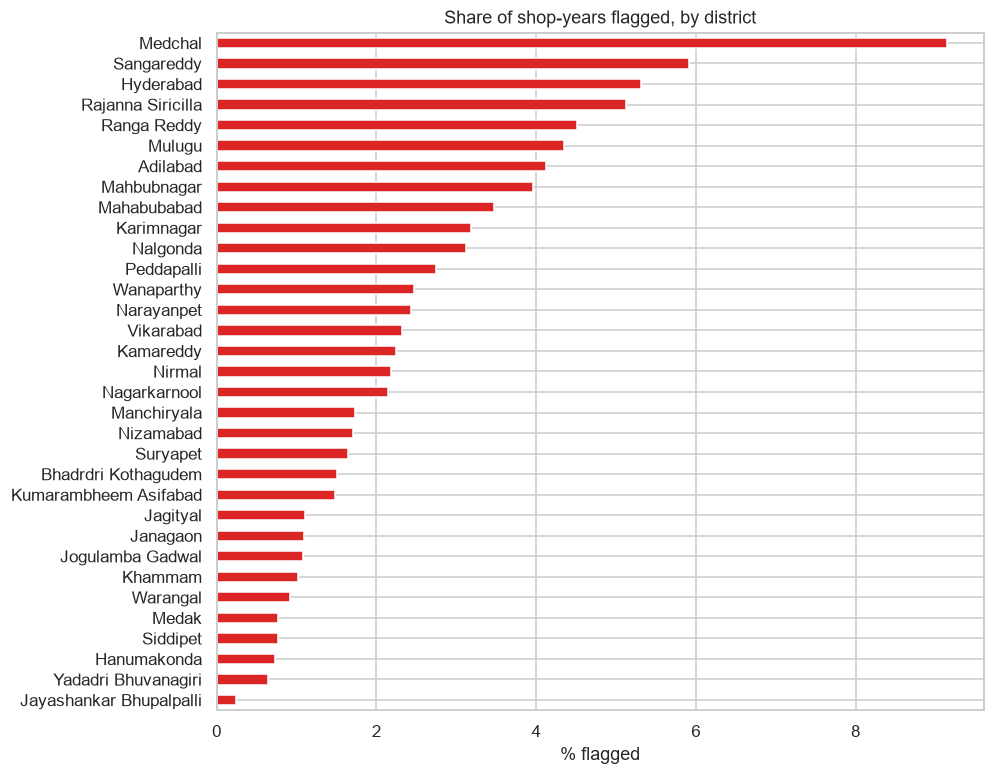

In [20]:
hot = df.groupby("distName").agg(shops=("shopNo","size"), flagged=("anomaly_flag","sum"))
hot["flagged_pct"] = hot["flagged"] / hot["shops"] * 100
fig, ax = plt.subplots(figsize=(9, 8))
hot.sort_values("flagged_pct").plot.barh(y="flagged_pct", ax=ax, legend=False, color="#dc2626")
ax.set(title="Share of shop-years flagged, by district", xlabel="% flagged", ylabel="")
save(fig, "14_anomaly_by_district"); plt.show()

### 6.3 Geospatial hotspot map
A Folium map of flagged shops and portability hubs, saved to `reports/hotspot_map.html`. The interactive version
with filters is in the Streamlit app.

In [21]:
import folium
from folium.plugins import HeatMap
pts = df[df["year"] == 2024].dropna(subset=["latitude", "longitude"])
m = folium.Map(location=[17.9, 79.1], zoom_start=7, tiles="OpenStreetMap")
HeatMap(pts.loc[pts["anomaly_flag"], ["latitude","longitude"]].values.tolist(), radius=11, blur=14,
        name="Anomaly density").add_to(m)
fg = folium.FeatureGroup(name="Portability hubs").add_to(m)
for _, r in pts[pts["portability_hub"]].iterrows():
    folium.CircleMarker([r["latitude"], r["longitude"]], radius=3, color="#2563eb", fill=True,
                        tooltip=f"Hub {r['shopNo']} · {r['distName']} · {r['portability_share']:.0%} portability").add_to(fg)
folium.LayerControl().add_to(m)
m.save(str(FIGURES_DIR.parent / "hotspot_map.html"))
m

## 7. Evaluation and business insights

### 7.1 Cluster purity vs Urban/Rural
The model **never saw** whether a shop is urban or rural. If a persona turns out to be almost entirely urban, the
clustering has rediscovered a real structural difference on its own, which is evidence the features are meaningful.

In [22]:
ct = pd.crosstab(df["persona"], df["area_type"], normalize="index").mul(100).round(1)
purity = (pd.crosstab(df["persona"], df["area_type"]).max(axis=1).sum() / len(df))
print(f"Overall purity vs Urban/Rural label: {purity:.1%}")
ct

Overall purity vs Urban/Rural label: 94.0%


area_type,Rural,Urban
persona,,
Antyodaya-Heavy Small Shops,88.800,11.200
Portability-Active Towns,89.500,10.500
Steady Rural Core,97.200,2.800
Urban Portability Hubs,0.000,100.000
Volatile Under-Utilized,88.200,11.800


Note that rural shops make up ~83% of all shop-years, so a high overall purity is partly expected. The
meaningful result is that **Urban Portability Hubs is 100% urban**, a segment the algorithm found without being
told.

### 7.2 Policy impact: how shops moved between personas, 2023 → 2024

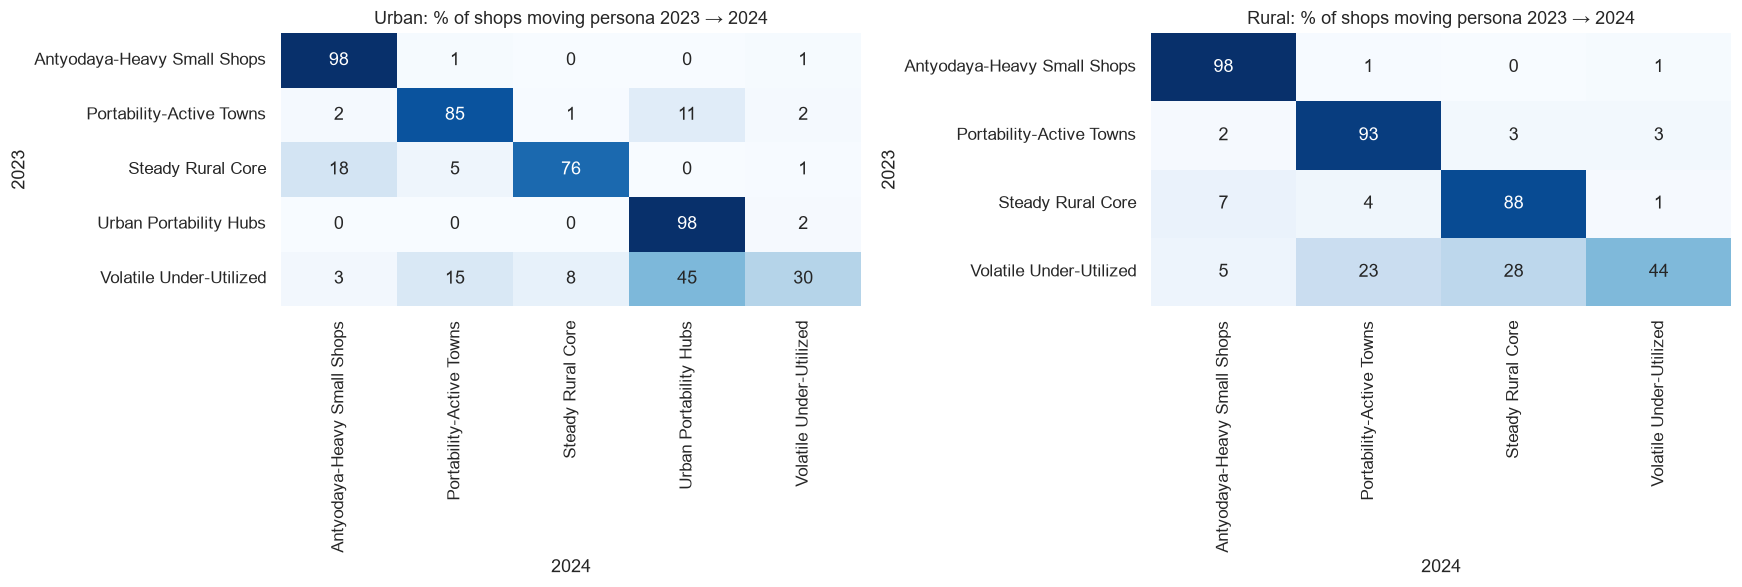

In [23]:
piv = df[df["year"].isin([2023, 2024])].pivot_table(index=["distCode","shopNo","area_type"], columns="year",
                                                    values="persona", aggfunc="first").dropna().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, area in zip(axes, ["Urban", "Rural"]):
    p = piv[piv["area_type"] == area]
    tr = pd.crosstab(p[2023], p[2024], normalize="index") * 100
    sns.heatmap(tr, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
    ax.set(title=f"{area}: % of shops moving persona 2023 → 2024", xlabel="2024", ylabel="2023")
plt.tight_layout(); save(fig, "15_persona_transitions"); plt.show()

**Reading the transitions:** the diagonal is shops that kept their persona. Most personas are stable (85-98%),
which shows the clusters capture lasting behaviour rather than noise. The off-diagonal moves tell the policy story:
* **Urban:** 11% of *Portability-Active Towns* became *Urban Portability Hubs* within one year, and 45% of urban
  *Volatile* shops settled into the hub pattern. As ONORC use grows, urban shops are being pulled towards the hub
  profile.
* **Rural:** the main movement is *out of* Volatile (only 44% stay), mostly into Steady Rural Core or
  Portability-Active Towns. Rural shops are stabilising, and a growing group is adopting portability.

In [24]:
share = df.groupby(["year", "area_type"])["portability_share"].median().unstack()
print("Median shop portability share by year:"); share.style.format("{:.1%}")

Median shop portability share by year:


area_type,Rural,Urban
year,,
2023,12.6%,67.6%
2024,13.5%,69.6%
2025,14.3%,71.1%


### 7.3 Key insights and recommendations

1. **Portability is structural, not marginal, and still growing.** 34% of all transactions statewide used
   another shop's card in 2023, rising to 37.5% in 2025. In the Hyderabad metro it's about two-thirds. ONORC has
   turned urban shops into service hubs for migrant households. → *Allocate stock from actual transactions, not
   from attached cards, in urban districts.*
2. **Five clear behavioural personas** (k = 5, silhouette ≈ 0.25) separate the routine majority from hubs,
   poverty-heavy shops and erratic shops. → *Set one monitoring threshold per persona instead of one statewide
   rule.*
3. **"Volatile Under-Utilized" shops are the audit priority.** They make up ~4% of shops but about 1 in 5 of them
   is flagged. Erratic volumes combined with low card uptake is the classic signature of irregular distribution
   or of inactive or duplicate cards on the rolls. → *Send field verification and e-KYC re-checks here first.*
4. **Peer-deviation flags (~2-3% of shop-years)** give inspectors a ranked list (`data/processed/anomalies.csv`).
   They are *leads to investigate*, not proof of fraud.
5. **Portability hubs** (top 5% portability share with ≥200 transactions a month) are concentrated. 60% are in
   the 3 metro districts, and they sit in only 109 of 585 circle offices (Uppal-2, Saroornagar-3, Balanagar-1 and
   Charminar-3 lead). → *Restock these offices fortnightly, and size their stock from the previous month's
   transactions rather than from registered cards.*
6. **Demand is flat across the year** (±2.5%), so a sudden spike at a shop is itself a warning sign, not
   seasonality.

**Limitations:** 2025 is partial (Jan-May). The urban label is district-level (the 3 metro districts), not
shop-level. Anomaly flags are statistical and need ground truth from field inspections to measure precision.